# 环境搭建、SpringCloud微服务(注册发现、服务调用、网关)


## 资料来源与阅读范围

本篇对应百度网盘「黑马程序员 Java 微服务项目《黑马头条》」day01：环境搭建、SpringCloud微服务（注册发现、服务调用、网关）。已取得并阅读完整Markdown讲义、第01天 `heima-leadnews.zip` 源码包和讲义原图压缩包；源码仅作静态参照。

课件中的虚拟机、Nacos、Docker、MySQL、微服务、网关和Nginx命令本次均未执行，未发送登录请求，也未把课件账号、密码、固定内网地址写入笔记；已用占位符脱敏。早期Springfox/Knife4j、Nacos和Spring Cloud版本需结合工程依赖核对。


## 资料校正与实践边界

- 课件用“密码+盐后MD5”演示登录流程；现代系统应使用适当成本的密码哈希，并限制失败次数，不能把MD5示例直接当生产密码方案。
- 网关过滤器示例用路径包含`/login`作为白名单；实践中应配置明确的公开路由，并校验JWT签名、算法、有效期、issuer/audience和用户状态。
- `allowedOrigins: "*"`只适合受控演示；带凭据的跨域请求需配置可信来源，CORS也不等于身份认证。
- `lb://leadnews-user`、`StripPrefix=1`和Nginx的`/app/`代理必须与当前Gateway路由逐层核对，直连服务URL不能和网关URL混用。
- 固定地址、端口、数据库密码、JWT密钥和测试账号属于环境配置，使用环境变量或配置中心管理，避免写进仓库、日志和接口集合。


## 1.课程对比

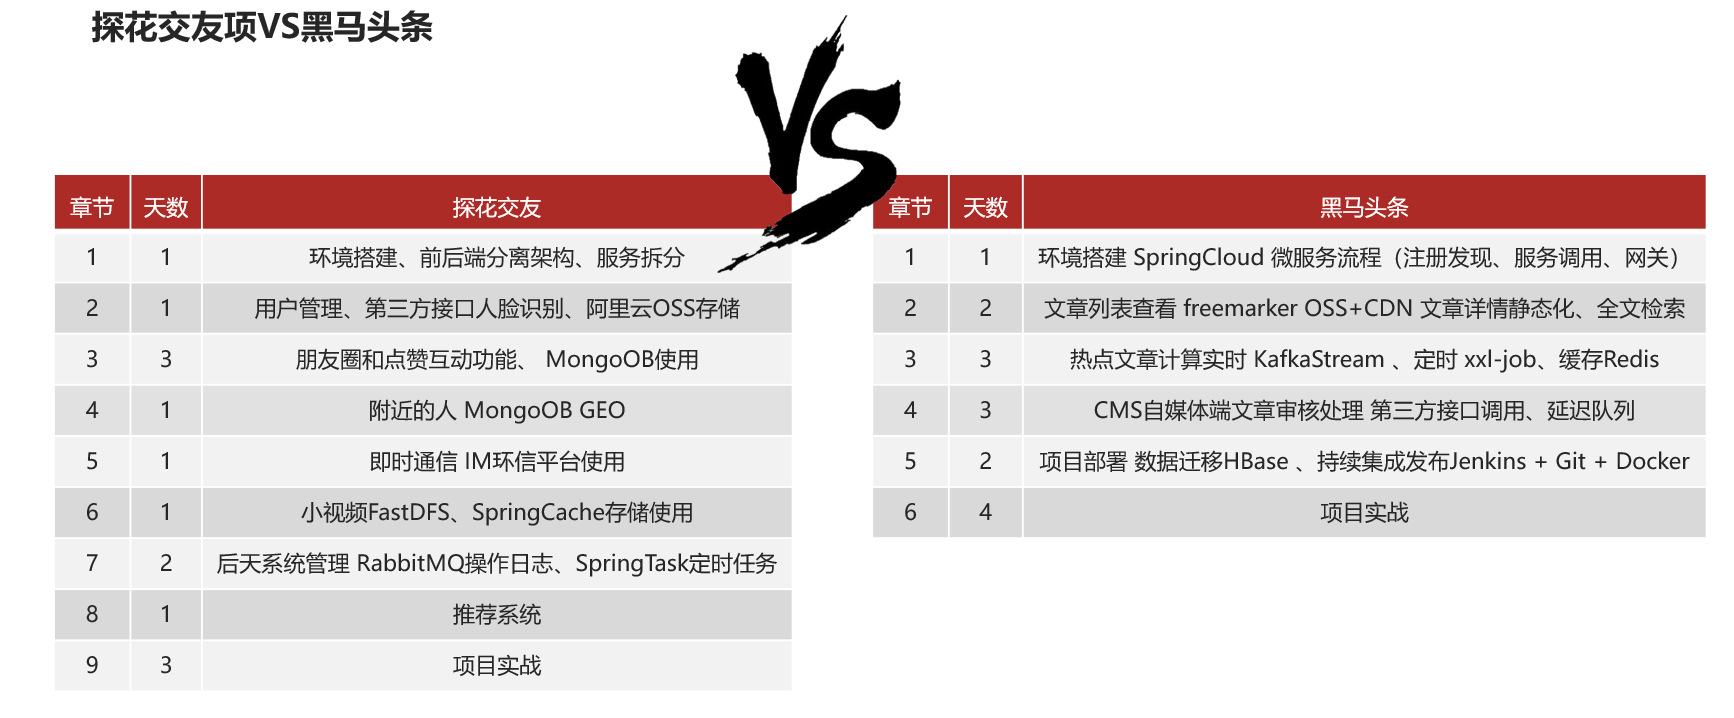


## 2.项目概述

### 2.1)能让你收获什么

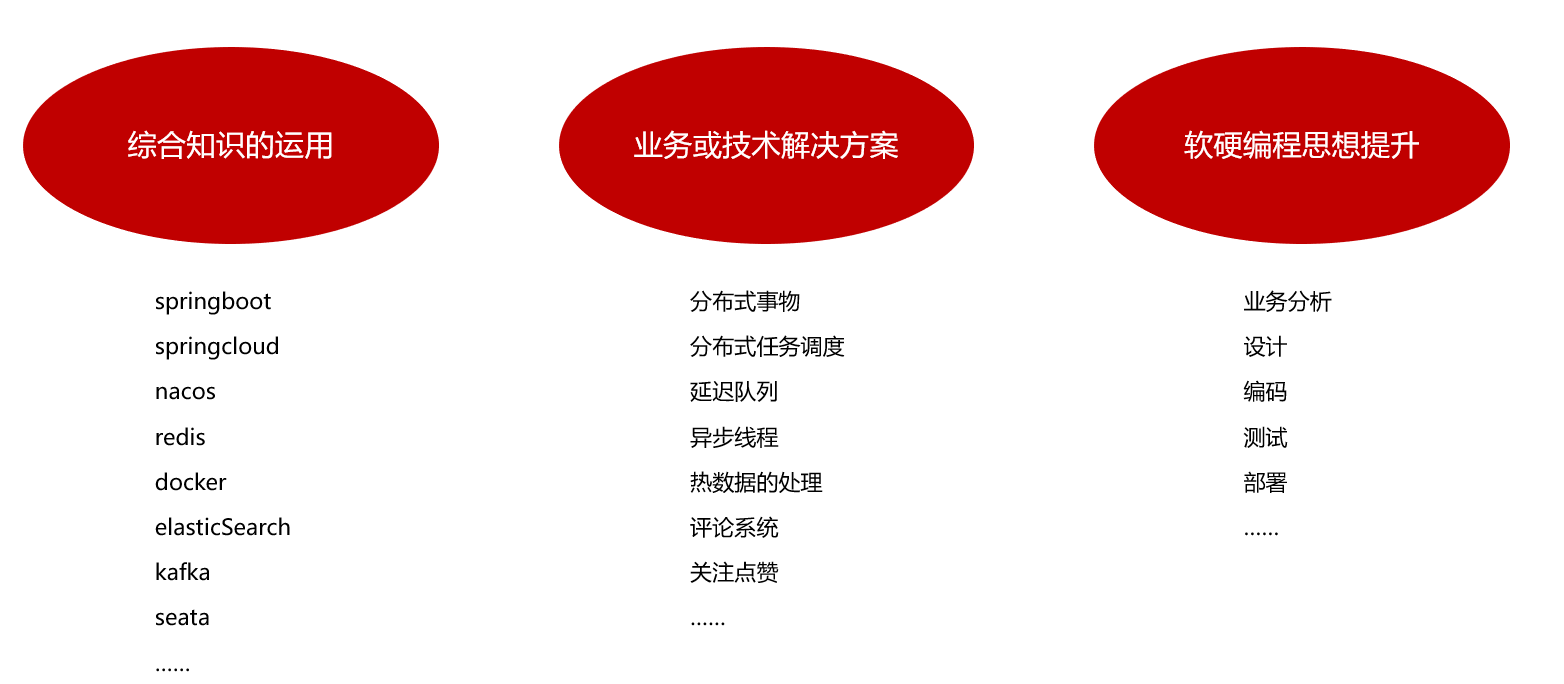

### 2.2)项目课程大纲

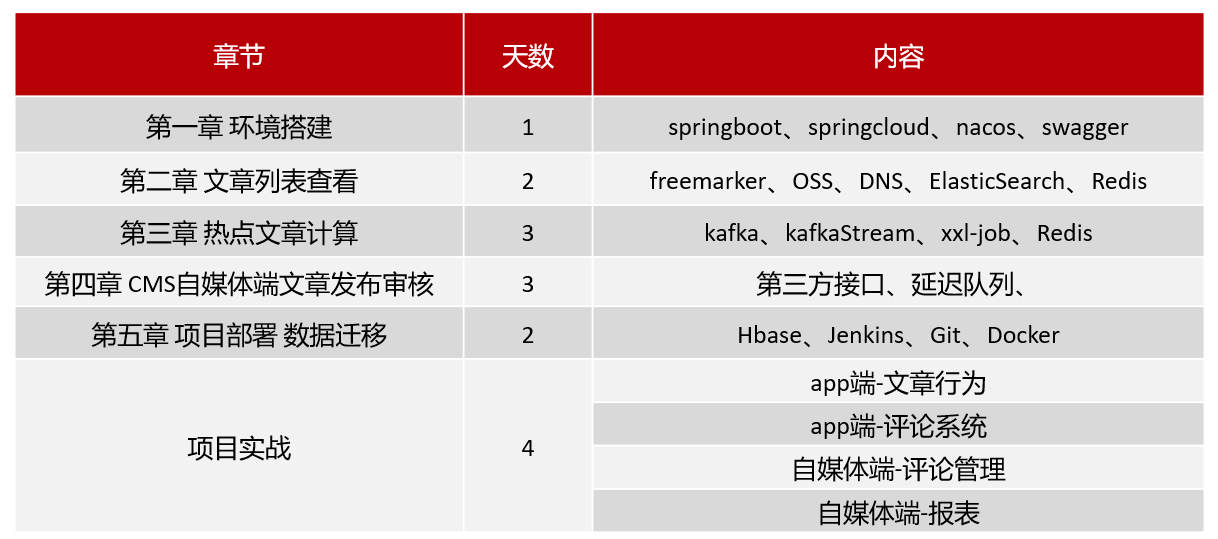



### 2.3)项目概述

随着智能手机的普及，人们更加习惯于通过手机来看新闻。由于生活节奏的加快，很多人只能利用碎片时间来获取信息，因此，对于移动资讯客户端的需求也越来越高。黑马头条项目正是在这样背景下开发出来。黑马头条项目采用当下火热的微服务+大数据技术架构实现。本项目主要着手于获取最新最热新闻资讯，通过大数据分析用户喜好精确推送咨询新闻

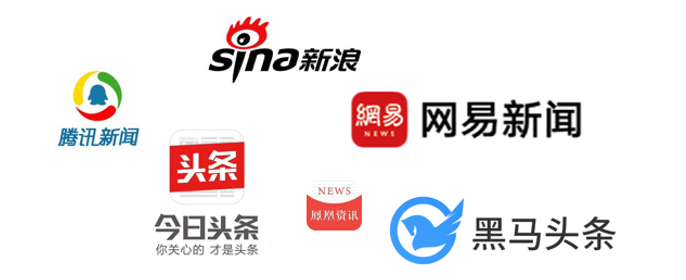



### 2.4)项目术语

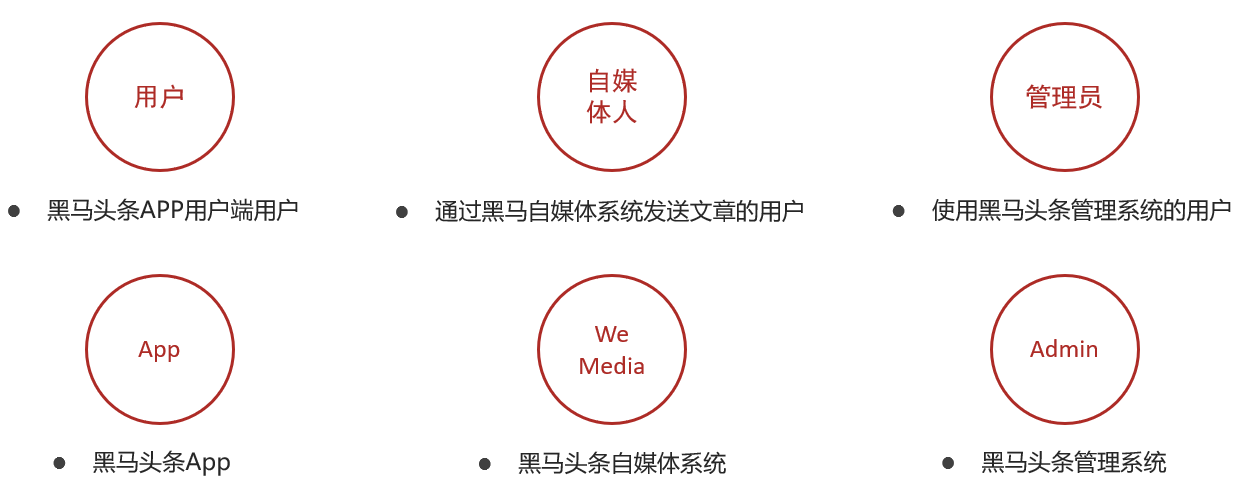



### 2.5)业务说明

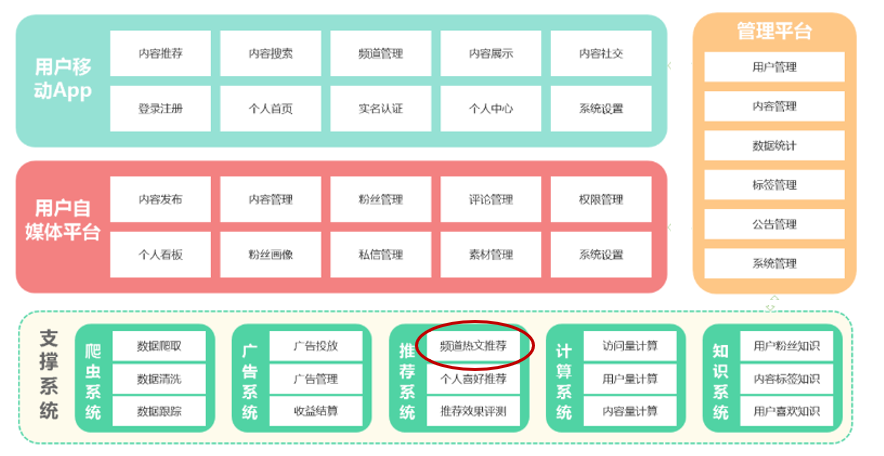

项目演示地址：

- 平台管理：[http://heima-admin-java.research.itcast.cn](http://heima-admin-java.research.itcast.cn/) 

- 自媒体：[http://heime-media-java.research.itcast.cn](http://heime-media-java.research.itcast.cn/) 

- app端：[http://heima-app-java.research.itcast.cn](http://heima-app-java.research.itcast.cn/) 

平台管理与自媒体为PC端，用电脑浏览器打开即可。

其中app端为移动端，打开方式有两种：                                                 

- 谷歌浏览器打开，调成移动端模式                      

- 手机浏览器打开或扫描右侧二维码

  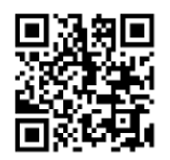


## 3.技术栈

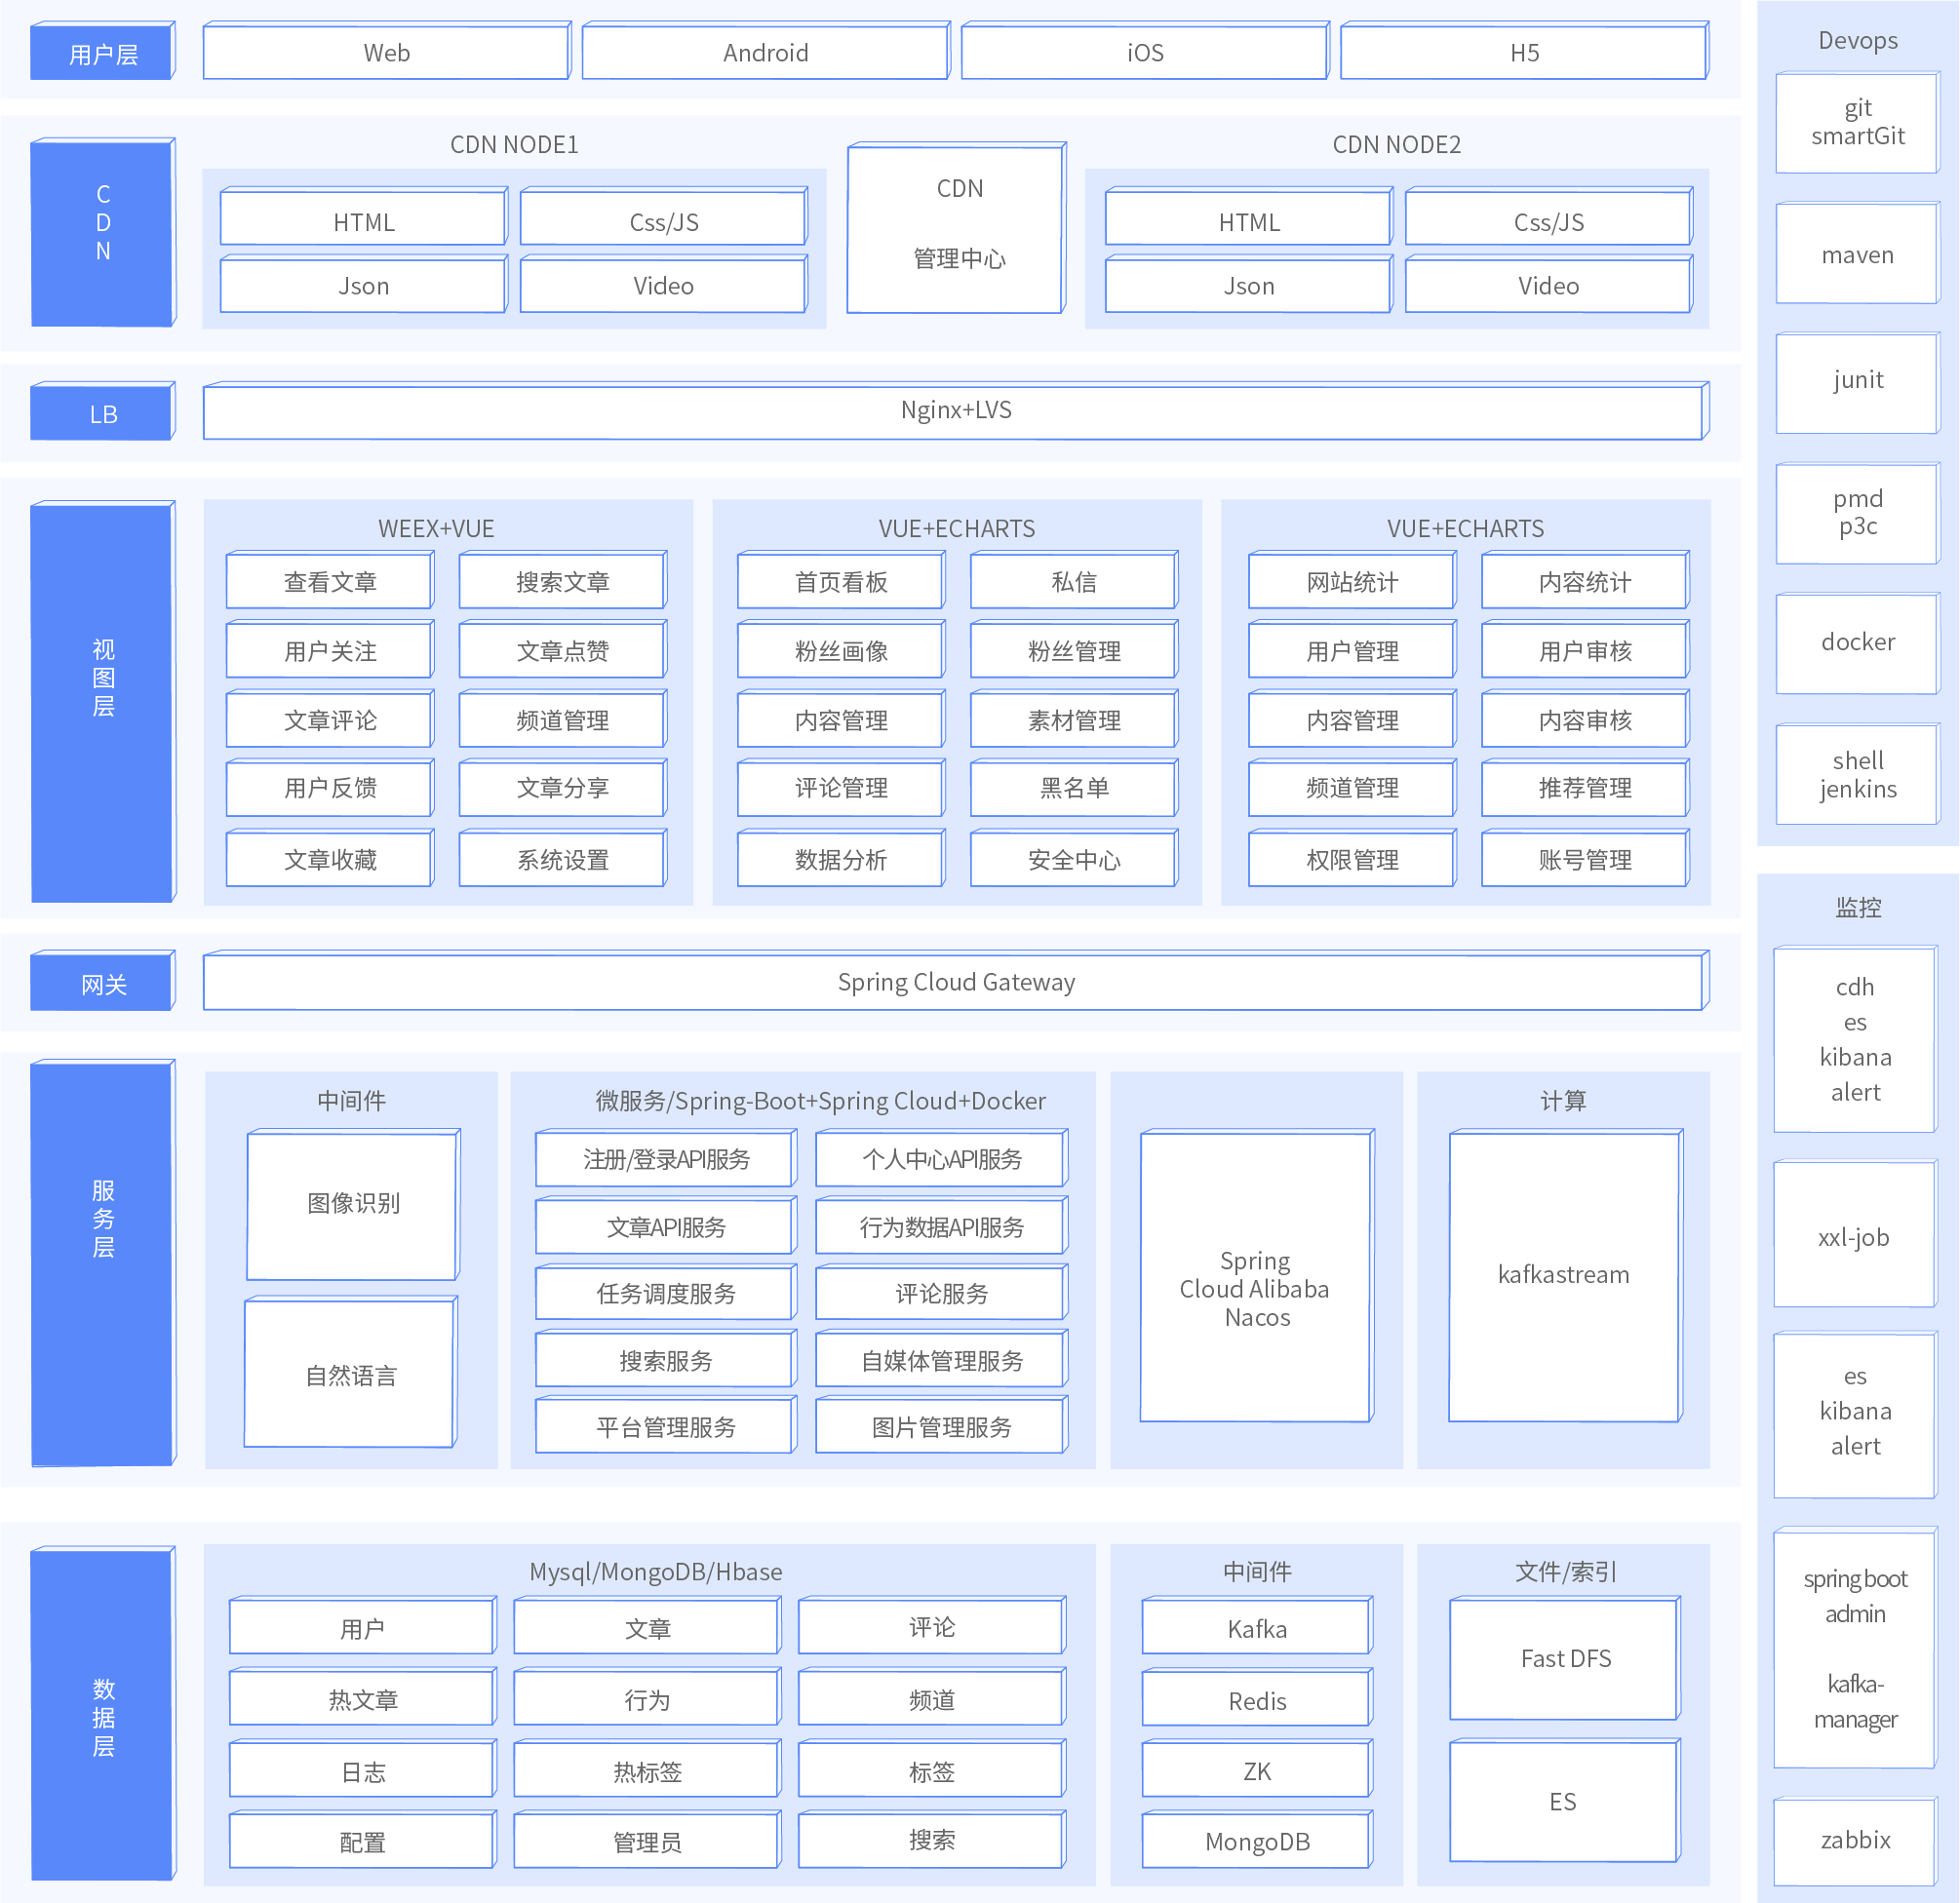

- Spring-Cloud-Gateway : 微服务之前架设的网关服务，实现服务注册中的API请求路由，以及控制流速控制和熔断处理都是常用的架构手段，而这些功能Gateway天然支持
- 运用Spring Boot快速开发框架，构建项目工程；并结合Spring Cloud全家桶技术，实现后端个人中心、自媒体、管理中心等微服务。
- 运用Spring Cloud Alibaba Nacos作为项目中的注册中心和配置中心
- 运用mybatis-plus作为持久层提升开发效率
- 运用Kafka完成内部系统消息通知；与客户端系统消息通知；以及实时数据计算
- 运用Redis缓存技术，实现热数据的计算，提升系统性能指标
- 使用Mysql存储用户数据，以保证上层数据查询的高性能
- 使用Mongo存储用户热数据，以保证用户热数据高扩展和高性能指标
- 使用FastDFS作为静态资源存储器，在其上实现热静态资源缓存、淘汰等功能
- 运用Hbase技术，存储系统中的冷数据，保证系统数据的可靠性
- 运用ES搜索技术，对冷数据、文章数据建立索引，以保证冷数据、文章查询性能
- 运用AI技术，来完成系统自动化功能，以提升效率及节省成本。比如实名认证自动化
- PMD&P3C : 静态代码扫描工具，在项目中扫描项目代码，检查异常点、优化点、代码规范等，为开发团队提供规范统一，提升项目代码质量


## 4.nacos环境搭建

### 4.1)虚拟机镜像准备

1)打开当天资料文件中的镜像，拷贝到一个地方，然后解压

2)解压后，双击ContOS7-hmtt.vmx文件，前提是电脑上已经安装了VMware

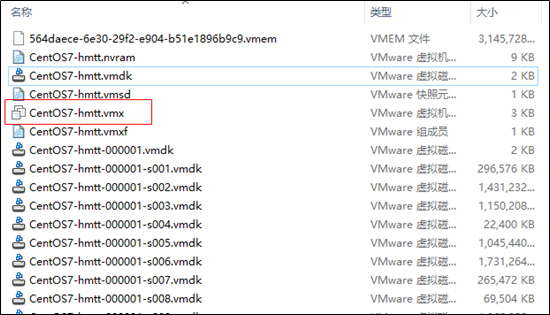

3) 修改虚拟网络地址（NAT）

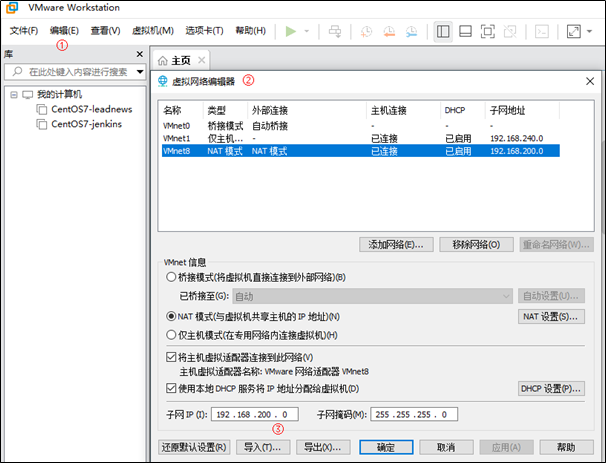

​		                                                        ①，选中VMware中的编辑

​		                                                        ②，选择虚拟网络编辑器

​		                                                        ③，找到NAT网卡，把网段改为200（当前挂载的虚拟机已固定ip地址）

4)修改虚拟机的网络模式为NAT

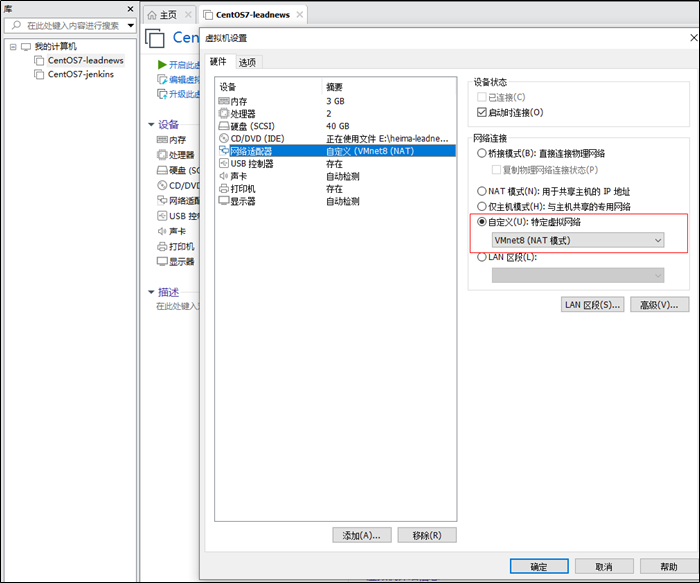

5)启动虚拟机，**用户名：root  密码：<PASSWORD_PLACEHOLDER>**，当前虚拟机的ip已手动固定（静态IP）, 地址为：**<nacos-host>**

6)使用FinalShell客户端链接

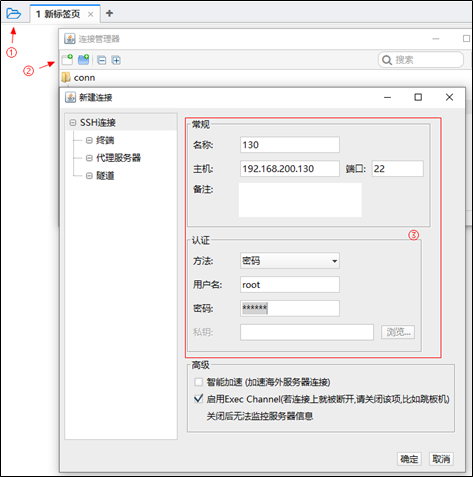





### 4.2)nacos安装

①：docker拉取镜像 

```shell
docker pull nacos/nacos-server:1.2.0
```

②：创建容器

```shell
docker run --env MODE=standalone --name nacos --restart=always  -d -p 8848:8848 nacos/nacos-server:1.2.0
```

- MODE=standalone 单机版

- --restart=always 开机启动

- -p 8848:8848  映射端口

- -d 创建一个守护式容器在后台运行

③：访问地址：http://<nacos-host>:8848/nacos 

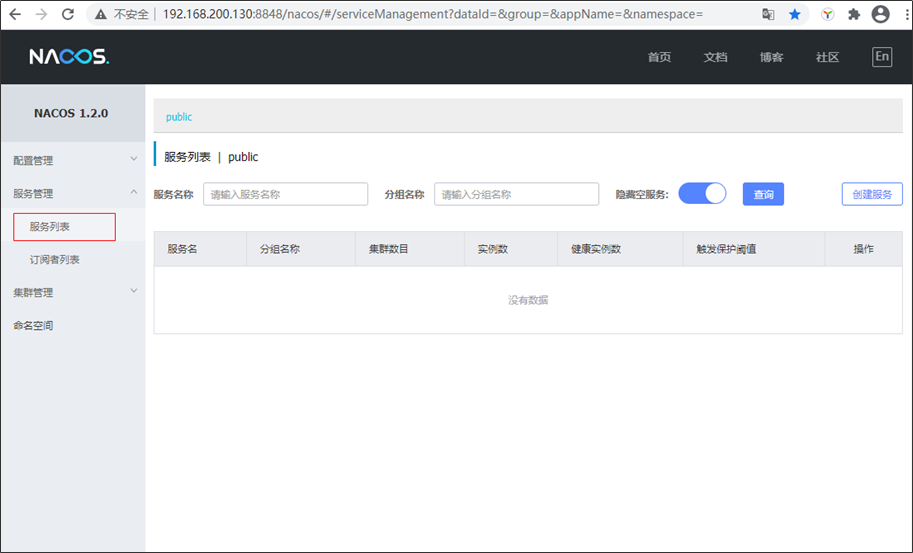


## 5.初始工程搭建

### 5.1)环境准备

①：项目依赖环境（需提前安装好）

- JDK1.8

- Intellij Idea

- maven-3.6.1

- Git



②：在当天资料中解压heima-leadnews.zip文件，拷贝到一个没有中文和空格的目录，使用idea打开即可

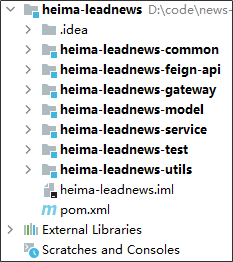

③：IDEA开发工具配置

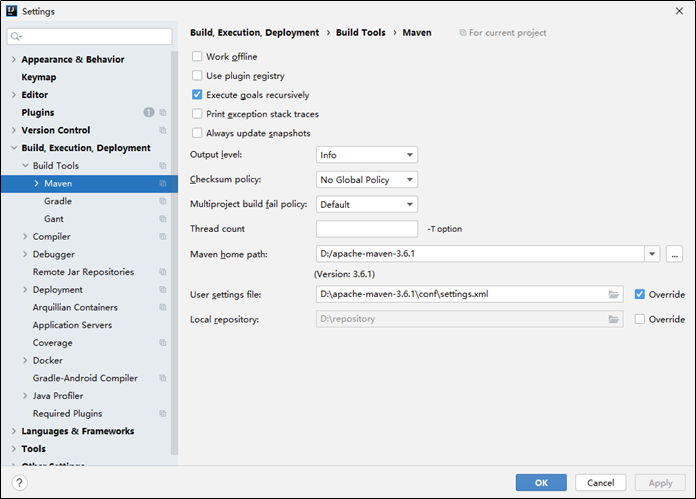

设置本地仓库，建议使用资料中提供好的仓库

④：设置项目编码格式

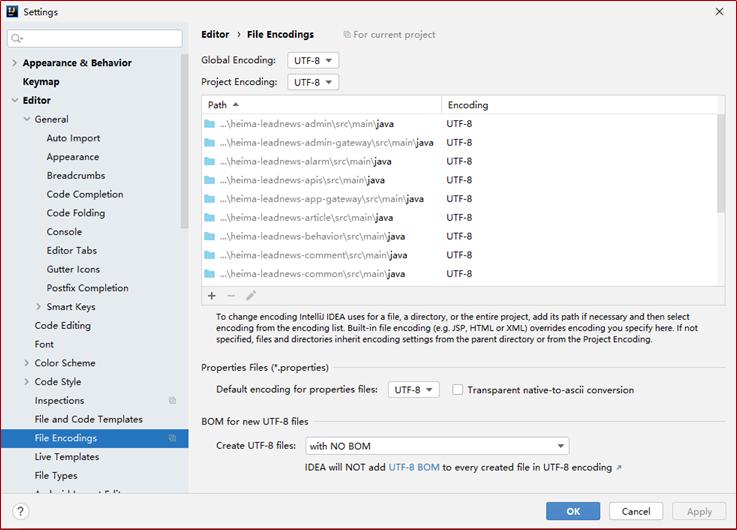

### 5.2)主体结构

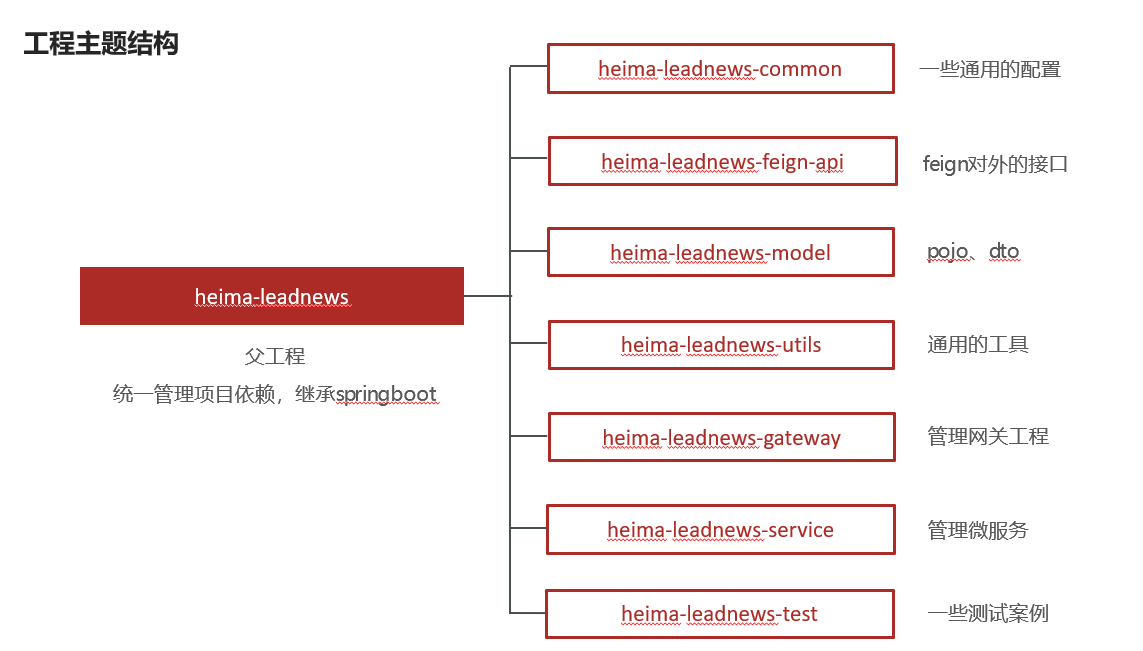


## 6.登录

### 6.1)需求分析

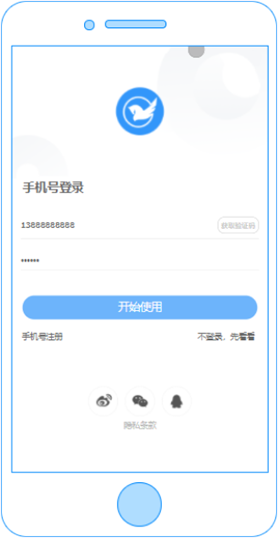

- 用户点击**开始使用**

  登录后的用户权限较大，可以查看，也可以操作（点赞，关注，评论）

- 用户点击**不登录，先看看**

​       游客只有查看的权限

### 6.2)表结构分析

关于app端用户相关的内容较多，可以单独设置一个库leadnews_user

| **表名称**       | **说明**          |
| ---------------- | ----------------- |
| ap_user          | APP用户信息表     |
| ap_user_fan      | APP用户粉丝信息表 |
| ap_user_follow   | APP用户关注信息表 |
| ap_user_realname | APP实名认证信息表 |

从当前资料中找到对应数据库并导入到mysql中



登录需要用到的是ap_user表，表结构如下：

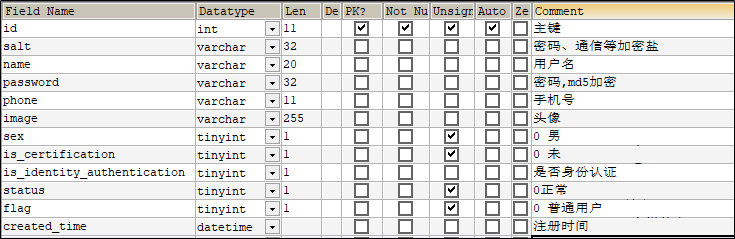

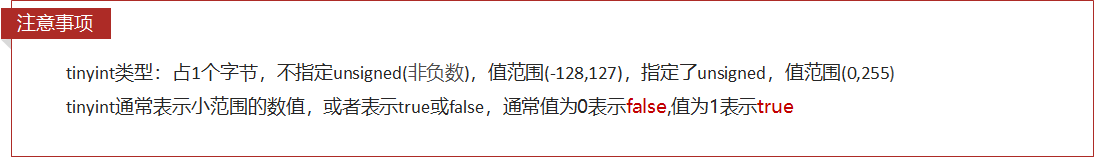

项目中的持久层使用的mybatis-plus，一般都使用mybais-plus逆向生成对应的实体类

app_user表对应的实体类如下：

```java
package com.heima.model.user.pojos;

import com.baomidou.mybatisplus.annotation.IdType;
import com.baomidou.mybatisplus.annotation.TableField;
import com.baomidou.mybatisplus.annotation.TableId;
import com.baomidou.mybatisplus.annotation.TableName;
import lombok.Data;

import java.io.Serializable;
import java.util.Date;

/**
 * <p>
 * APP用户信息表
 * </p>
 *
 * @author itheima
 */
@Data
@TableName("ap_user")
public class ApUser implements Serializable {

    private static final long serialVersionUID = 1L;

    /**
     * 主键
     */
    @TableId(value = "id", type = IdType.AUTO)
    private Integer id;

    /**
     * 密码、通信等加密盐
     */
    @TableField("salt")
    private String salt;

    /**
     * 用户名
     */
    @TableField("name")
    private String name;

    /**
     * 密码,md5加密
     */
    @TableField("password")
    private String password;

    /**
     * 手机号
     */
    @TableField("phone")
    private String phone;

    /**
     * 头像
     */
    @TableField("image")
    private String image;

    /**
     * 0 男
            1 女
            2 未知
     */
    @TableField("sex")
    private Boolean sex;

    /**
     * 0 未
            1 是
     */
    @TableField("is_certification")
    private Boolean certification;

    /**
     * 是否身份认证
     */
    @TableField("is_identity_authentication")
    private Boolean identityAuthentication;

    /**
     * 0正常
            1锁定
     */
    @TableField("status")
    private Boolean status;

    /**
     * 0 普通用户
            1 自媒体人
            2 大V
     */
    @TableField("flag")
    private Short flag;

    /**
     * 注册时间
     */
    @TableField("created_time")
    private Date createdTime;

}
```

手动加密（md5+随机字符串）

md5是不可逆加密，md5相同的密码每次加密都一样，不太安全。在md5的基础上手动加盐（salt）处理

注册->生成盐

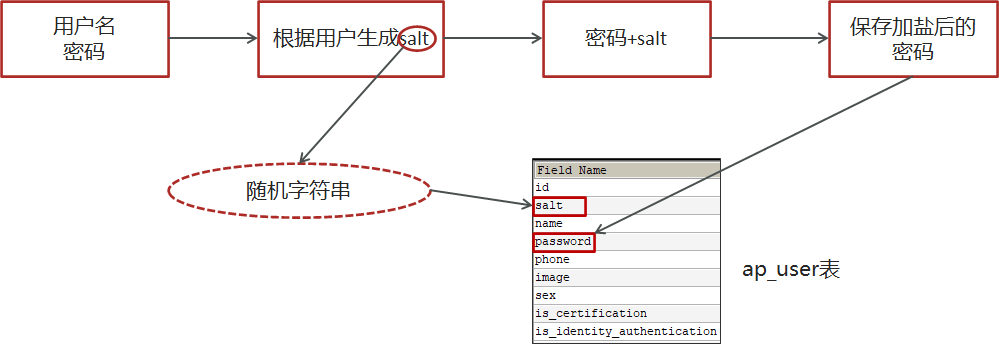

登录->使用盐来配合验证

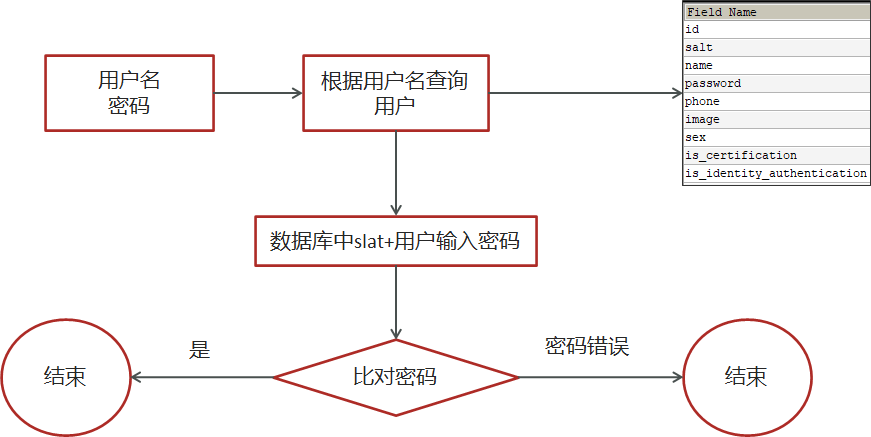



### 6.3)思路分析

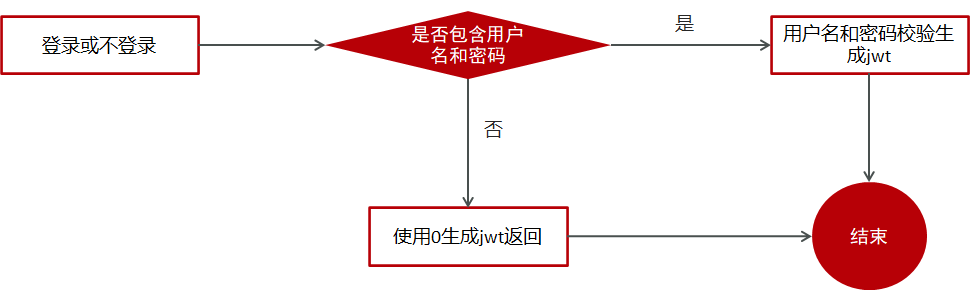

1，用户输入了用户名和密码进行登录，校验成功后返回jwt(基于当前用户的id生成)

2，用户游客登录，生成jwt返回(基于默认值0生成)‘



### 6.4)**运营端微服务搭建**

在heima-leadnews-service下创建工程heima-leadnews-user

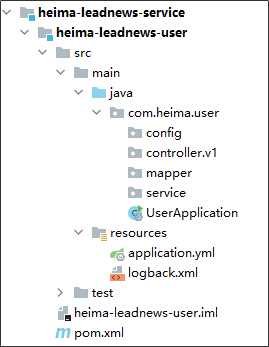

引导类

```java
package com.heima.user;

import org.mybatis.spring.annotation.MapperScan;
import org.springframework.boot.SpringApplication;
import org.springframework.boot.autoconfigure.SpringBootApplication;
import org.springframework.cloud.client.discovery.EnableDiscoveryClient;

@SpringBootApplication
@EnableDiscoveryClient
@MapperScan("com.heima.user.mapper")
public class UserApplication {

    public static void main(String[] args) {
        SpringApplication.run(UserApplication.class,args);
    }
}
```

bootstrap.yml

```yaml
server:
  port: 51801
spring:
  application:
    name: leadnews-user
  cloud:
    nacos:
      discovery:
        server-addr: <nacos-host>:8848
      config:
        server-addr: <nacos-host>:8848
        file-extension: yml
```

在nacos中创建配置文件

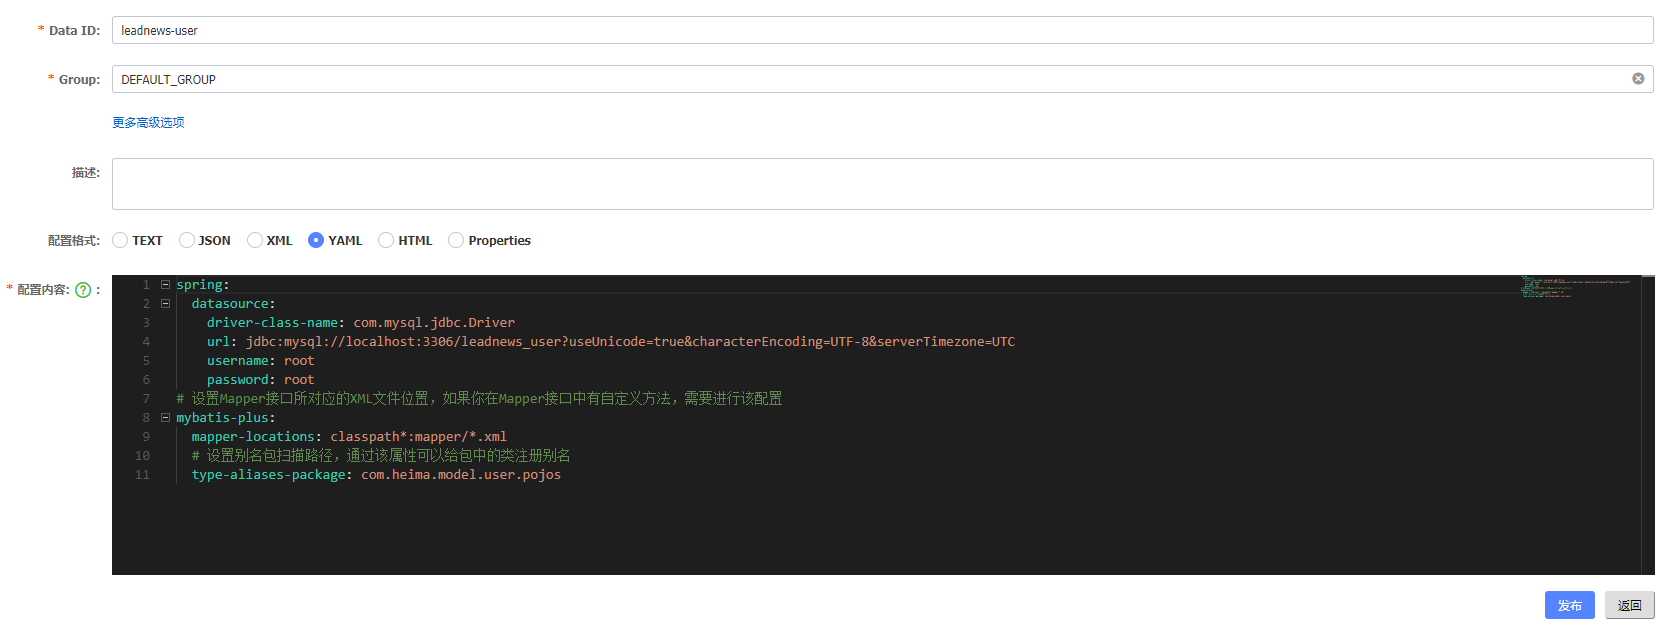

```yaml
spring:
  datasource:
    driver-class-name: com.mysql.jdbc.Driver
    url: jdbc:mysql://<mysql-host>:3306/leadnews_user?useUnicode=true&characterEncoding=UTF-8&serverTimezone=UTC
    username: root
    password: <PASSWORD_PLACEHOLDER>
# 设置Mapper接口所对应的XML文件位置，如果你在Mapper接口中有自定义方法，需要进行该配置
mybatis-plus:
  mapper-locations: classpath*:mapper/*.xml
  # 设置别名包扫描路径，通过该属性可以给包中的类注册别名
  type-aliases-package: com.heima.model.user.pojos
```

logback.xml

```xml
<?xml version="1.0" encoding="UTF-8"?>

<configuration>
    <!--定义日志文件的存储地址,使用绝对路径-->
    <property name="LOG_HOME" value="<log-directory>"/>

    <!-- Console 输出设置 -->
    <appender name="CONSOLE" class="ch.qos.logback.core.ConsoleAppender">
        <encoder>
            <!--格式化输出：%d表示日期，%thread表示线程名，%-5level：级别从左显示5个字符宽度%msg：日志消息，%n是换行符-->
            <pattern>%d{yyyy-MM-dd HH:mm:ss.SSS} [%thread] %-5level %logger{36} - %msg%n</pattern>
            <charset>utf8</charset>
        </encoder>
    </appender>

    <!-- 按照每天生成日志文件 -->
    <appender name="FILE" class="ch.qos.logback.core.rolling.RollingFileAppender">
        <rollingPolicy class="ch.qos.logback.core.rolling.TimeBasedRollingPolicy">
            <!--日志文件输出的文件名-->
            <fileNamePattern>${LOG_HOME}/leadnews.%d{yyyy-MM-dd}.log</fileNamePattern>
        </rollingPolicy>
        <encoder>
            <pattern>%d{yyyy-MM-dd HH:mm:ss.SSS} [%thread] %-5level %logger{36} - %msg%n</pattern>
        </encoder>
    </appender>

    <!-- 异步输出 -->
    <appender name="ASYNC" class="ch.qos.logback.classic.AsyncAppender">
        <!-- 不丢失日志.默认的,如果队列的80%已满,则会丢弃TRACT、DEBUG、INFO级别的日志 -->
        <discardingThreshold>0</discardingThreshold>
        <!-- 更改默认的队列的深度,该值会影响性能.默认值为256 -->
        <queueSize>512</queueSize>
        <!-- 添加附加的appender,最多只能添加一个 -->
        <appender-ref ref="FILE"/>
    </appender>


    <logger name="org.apache.ibatis.cache.decorators.LoggingCache" level="DEBUG" additivity="false">
        <appender-ref ref="CONSOLE"/>
    </logger>
    <logger name="org.springframework.boot" level="debug"/>
    <root level="info">
        <!--<appender-ref ref="ASYNC"/>-->
        <appender-ref ref="FILE"/>
        <appender-ref ref="CONSOLE"/>
    </root>
</configuration>
```



### 6.4)登录功能实现

①：接口定义

```java
@RestController
@RequestMapping("/api/v1/login")
public class ApUserLoginController {

    @PostMapping("/login_auth")
    public ResponseResult login(@RequestBody LoginDto dto) {
        return null;
    }
}
```

②：持久层mapper

```java
package com.heima.user.mapper;

import com.baomidou.mybatisplus.core.mapper.BaseMapper;
import com.heima.model.user.pojos.ApUser;
import org.apache.ibatis.annotations.Mapper;

@Mapper
public interface ApUserMapper extends BaseMapper<ApUser> {
}
```

③：业务层service

```java
package com.heima.user.service;

import com.baomidou.mybatisplus.extension.service.IService;
import com.heima.model.common.dtos.ResponseResult;
import com.heima.model.user.dtos.LoginDto;
import com.heima.model.user.pojos.ApUser;

public interface ApUserService extends IService<ApUser>{

    /**
     * app端登录
     * @param dto
     * @return
     */
    public ResponseResult login(LoginDto dto);
    
}
```

实现类：

```java
package com.heima.user.service.impl;

import com.baomidou.mybatisplus.core.toolkit.Wrappers;
import com.baomidou.mybatisplus.extension.service.impl.ServiceImpl;
import com.heima.model.common.dtos.ResponseResult;
import com.heima.model.common.enums.AppHttpCodeEnum;
import com.heima.model.user.dtos.LoginDto;
import com.heima.model.user.pojos.ApUser;
import com.heima.user.mapper.ApUserMapper;
import com.heima.user.service.ApUserService;
import com.heima.utils.common.AppJwtUtil;
import org.apache.commons.lang3.StringUtils;
import org.springframework.stereotype.Service;
import org.springframework.util.DigestUtils;

import java.util.HashMap;
import java.util.Map;


@Service
public class ApUserServiceImpl extends ServiceImpl<ApUserMapper, ApUser> implements ApUserService {

    @Override
    public ResponseResult login(LoginDto dto) {

        //1.正常登录（手机号+密码登录）
        if (!StringUtils.isBlank(dto.getPhone()) && !StringUtils.isBlank(dto.getPassword())) {
            //1.1查询用户
            ApUser apUser = getOne(Wrappers.<ApUser>lambdaQuery().eq(ApUser::getPhone, dto.getPhone()));
            if (apUser == null) {
                return ResponseResult.errorResult(AppHttpCodeEnum.DATA_NOT_EXIST,"用户不存在");
            }

            //1.2 比对密码
            String salt = apUser.getSalt();
            String pswd = dto.getPassword();
            pswd = DigestUtils.md5DigestAsHex((pswd + salt).getBytes());
            if (!pswd.equals(apUser.getPassword())) {
                return ResponseResult.errorResult(AppHttpCodeEnum.LOGIN_PASSWORD_ERROR);
            }
            //1.3 返回数据  jwt
            Map<String, Object> map = new HashMap<>();
            map.put("token", AppJwtUtil.getToken(apUser.getId().longValue()));
            apUser.setSalt("");
            apUser.setPassword("");
            map.put("user", apUser);
            return ResponseResult.okResult(map);
        } else {
            //2.游客  同样返回token  id = 0
            Map<String, Object> map = new HashMap<>();
            map.put("token", AppJwtUtil.getToken(0l));
            return ResponseResult.okResult(map);
        }
    }
}
```

④：控制层controller

```java
package com.heima.user.controller.v1;

import com.heima.model.common.dtos.ResponseResult;
import com.heima.model.user.dtos.LoginDto;
import com.heima.user.service.ApUserService;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.PostMapping;
import org.springframework.web.bind.annotation.RequestBody;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;

@RestController
@RequestMapping("/api/v1/login")
public class ApUserLoginController {

    @Autowired
    private ApUserService apUserService;

    @PostMapping("/login_auth")
    public ResponseResult login(@RequestBody LoginDto dto) {
        return apUserService.login(dto);
    }
}
```


## 7.接口工具postman、swagger、knife4j

### 7.1)postman

Postman是一款功能强大的网页调试与发送网页HTTP请求的Chrome插件。postman被500万开发者和超100,000家公司用于每月访问1.3亿个API。

官方网址：https://www.postman.com/

解压资料文件夹中的软件，安装即可

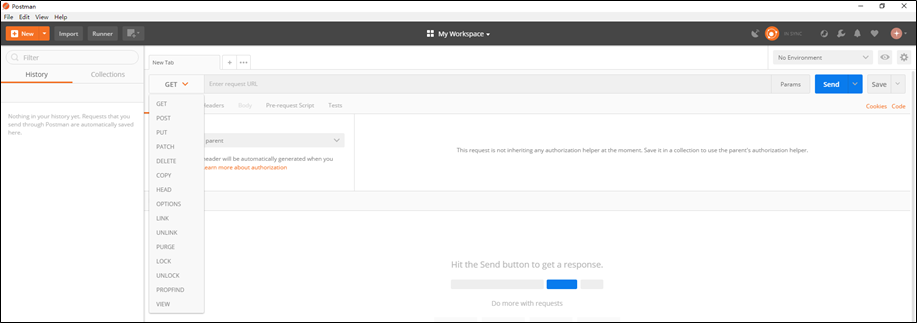

通常的接口测试查看请求和响应，下面是登录请求的测试

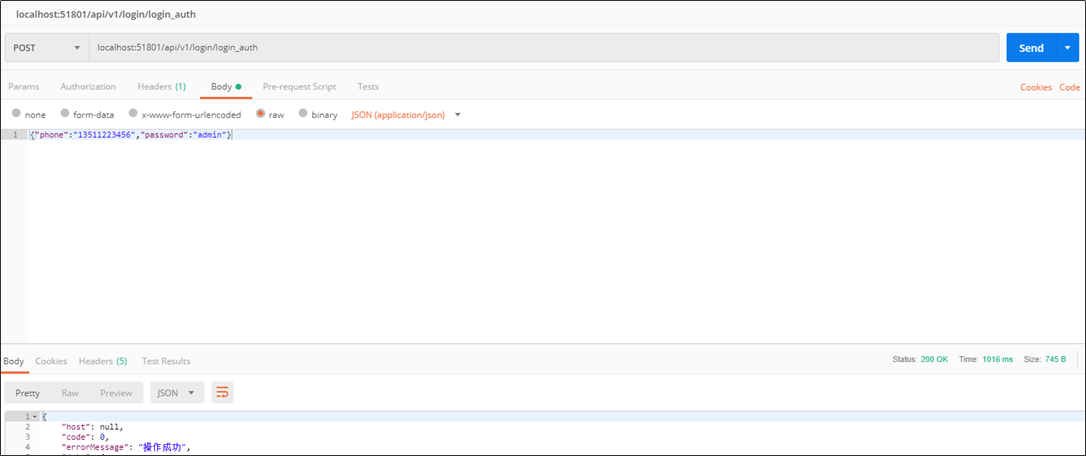

### 7.2)swagger

(1)简介

Swagger 是一个规范和完整的框架，用于生成、描述、调用和可视化 RESTful 风格的 Web 服务(<https://swagger.io/>)。 它的主要作用是：

1. 使得前后端分离开发更加方便，有利于团队协作

2. 接口的文档在线自动生成，降低后端开发人员编写接口文档的负担

3. 功能测试 

   Spring已经将Swagger纳入自身的标准，建立了Spring-swagger项目，现在叫Springfox。通过在项目中引入Springfox ，即可非常简单快捷的使用Swagger。

(2)SpringBoot集成Swagger

- 引入依赖,在heima-leadnews-model和heima-leadnews-common模块中引入该依赖

  ```xml
  <dependency>
      <groupId>io.springfox</groupId>
      <artifactId>springfox-swagger2</artifactId>
  </dependency>
  <dependency>
      <groupId>io.springfox</groupId>
      <artifactId>springfox-swagger-ui</artifactId>
  </dependency>
  ```

只需要在heima-leadnews-common中进行配置即可，因为其他微服务工程都直接或间接依赖即可。

- 在heima-leadnews-common工程中添加一个配置类

新增：com.heima.common.swagger.SwaggerConfiguration

```java
package com.heima.common.swagger;

import org.springframework.context.annotation.Bean;
import org.springframework.context.annotation.Configuration;
import springfox.documentation.builders.ApiInfoBuilder;
import springfox.documentation.builders.PathSelectors;
import springfox.documentation.builders.RequestHandlerSelectors;
import springfox.documentation.service.ApiInfo;
import springfox.documentation.service.Contact;
import springfox.documentation.spi.DocumentationType;
import springfox.documentation.spring.web.plugins.Docket;
import springfox.documentation.swagger2.annotations.EnableSwagger2;

@Configuration
@EnableSwagger2
public class SwaggerConfiguration {

   @Bean
   public Docket buildDocket() {
      return new Docket(DocumentationType.SWAGGER_2)
              .apiInfo(buildApiInfo())
              .select()
              // 要扫描的API(Controller)基础包
              .apis(RequestHandlerSelectors.basePackage("com.heima"))
              .paths(PathSelectors.any())
              .build();
   }

   private ApiInfo buildApiInfo() {
      Contact contact = new Contact("黑马程序员","","");
      return new ApiInfoBuilder()
              .title("黑马头条-平台管理API文档")
              .description("黑马头条后台api")
              .contact(contact)
              .version("1.0.0").build();
   }
}
```

在heima-leadnews-common模块中的resources目录中新增以下目录和文件

文件：resources/META-INF/Spring.factories

```java
org.springframework.boot.autoconfigure.EnableAutoConfiguration=\
  com.heima.common.swagger.SwaggerConfiguration
```

（3）Swagger常用注解

在Java类中添加Swagger的注解即可生成Swagger接口文档，常用Swagger注解如下：

@Api：修饰整个类，描述Controller的作用  

@ApiOperation：描述一个类的一个方法，或者说一个接口  

@ApiParam：单个参数的描述信息  

@ApiModel：用对象来接收参数  

@ApiModelProperty：用对象接收参数时，描述对象的一个字段  

@ApiResponse：HTTP响应其中1个描述  

@ApiResponses：HTTP响应整体描述  

@ApiIgnore：使用该注解忽略这个API  

@ApiError ：发生错误返回的信息  

@ApiImplicitParam：一个请求参数  

@ApiImplicitParams：多个请求参数的描述信息



 @ApiImplicitParam属性：

| 属性         | 取值   | 作用                                          |
| ------------ | ------ | --------------------------------------------- |
| paramType    |        | 查询参数类型                                  |
|              | path   | 以地址的形式提交数据                          |
|              | query  | 直接跟参数完成自动映射赋值                    |
|              | body   | 以流的形式提交 仅支持POST                     |
|              | header | 参数在request headers 里边提交                |
|              | form   | 以form表单的形式提交 仅支持POST               |
| dataType     |        | 参数的数据类型 只作为标志说明，并没有实际验证 |
|              | Long   |                                               |
|              | String |                                               |
| name         |        | 接收参数名                                    |
| value        |        | 接收参数的意义描述                            |
| required     |        | 参数是否必填                                  |
|              | true   | 必填                                          |
|              | false  | 非必填                                        |
| defaultValue |        | 默认值                                        |

我们在ApUserLoginController中添加Swagger注解，代码如下所示：

```java
@RestController
@RequestMapping("/api/v1/login")
@Api(value = "app端用户登录", tags = "ap_user", description = "app端用户登录API")
public class ApUserLoginController {

    @Autowired
    private ApUserService apUserService;

    @PostMapping("/login_auth")
    @ApiOperation("用户登录")
    public ResponseResult login(@RequestBody LoginDto dto){
        return apUserService.login(dto);
    }
}
```

LoginDto

```java
@Data
public class LoginDto {

    /**
     * 手机号
     */
    @ApiModelProperty(value="手机号",required = true)
    private String phone;

    /**
     * 密码
     */
    @ApiModelProperty(value="密码",required = true)
    private String password;
}
```

启动user微服务，访问地址：http://localhost:51801/swagger-ui.html



### 7.3)knife4j

(1)简介

knife4j是为Java MVC框架集成Swagger生成Api文档的增强解决方案,前身是swagger-bootstrap-ui,取名kni4j是希望它能像一把匕首一样小巧,轻量,并且功能强悍!

gitee地址：https://gitee.com/xiaoym/knife4j

官方文档：https://doc.xiaominfo.com/

效果演示：http://knife4j.xiaominfo.com/doc.html

(2)核心功能

该UI增强包主要包括两大核心功能：文档说明 和 在线调试

- 文档说明：根据Swagger的规范说明，详细列出接口文档的说明，包括接口地址、类型、请求示例、请求参数、响应示例、响应参数、响应码等信息，使用swagger-bootstrap-ui能根据该文档说明，对该接口的使用情况一目了然。
- 在线调试：提供在线接口联调的强大功能，自动解析当前接口参数,同时包含表单验证，调用参数可返回接口响应内容、headers、Curl请求命令实例、响应时间、响应状态码等信息，帮助开发者在线调试，而不必通过其他测试工具测试接口是否正确,简介、强大。
- 个性化配置：通过个性化ui配置项，可自定义UI的相关显示信息
- 离线文档：根据标准规范，生成的在线markdown离线文档，开发者可以进行拷贝生成markdown接口文档，通过其他第三方markdown转换工具转换成html或pdf，这样也可以放弃swagger2markdown组件
- 接口排序：自1.8.5后，ui支持了接口排序功能，例如一个注册功能主要包含了多个步骤,可以根据swagger-bootstrap-ui提供的接口排序规则实现接口的排序，step化接口操作，方便其他开发者进行接口对接

(3)快速集成

- 在heima-leadnews-common模块中的`pom.xml`文件中引入`knife4j`的依赖,如下：

```xml
<dependency>
     <groupId>com.github.xiaoymin</groupId>
     <artifactId>knife4j-spring-boot-starter</artifactId>
</dependency>
```

- 创建Swagger配置文件

在heima-leadnews-common模块中新建配置类

新建Swagger的配置文件`SwaggerConfiguration.java`文件,创建springfox提供的Docket分组对象,代码如下：

```java
package com.heima.common.knife4j;

import com.github.xiaoymin.knife4j.spring.annotations.EnableKnife4j;
import org.springframework.context.annotation.Bean;
import org.springframework.context.annotation.Configuration;
import org.springframework.context.annotation.Import;
import springfox.bean.validators.configuration.BeanValidatorPluginsConfiguration;
import springfox.documentation.builders.ApiInfoBuilder;
import springfox.documentation.builders.PathSelectors;
import springfox.documentation.builders.RequestHandlerSelectors;
import springfox.documentation.service.ApiInfo;
import springfox.documentation.spi.DocumentationType;
import springfox.documentation.spring.web.plugins.Docket;
import springfox.documentation.swagger2.annotations.EnableSwagger2;

@Configuration
@EnableSwagger2
@EnableKnife4j
@Import(BeanValidatorPluginsConfiguration.class)
public class Swagger2Configuration {

    @Bean(value = "defaultApi2")
    public Docket defaultApi2() {
        Docket docket=new Docket(DocumentationType.SWAGGER_2)
                .apiInfo(apiInfo())
                //分组名称
                .groupName("1.0")
                .select()
                //这里指定Controller扫描包路径
                .apis(RequestHandlerSelectors.basePackage("com.heima"))
                .paths(PathSelectors.any())
                .build();
        return docket;
    }
    private ApiInfo apiInfo() {
        return new ApiInfoBuilder()
                .title("黑马头条API文档")
                .description("黑马头条API文档")
                .version("1.0")
                .build();
    }
}
```

以上有两个注解需要特别说明，如下表：

| 注解              | 说明                                                         |
| ----------------- | ------------------------------------------------------------ |
| `@EnableSwagger2` | 该注解是Springfox-swagger框架提供的使用Swagger注解，该注解必须加 |
| `@EnableKnife4j`  | 该注解是`knife4j`提供的增强注解,Ui提供了例如动态参数、参数过滤、接口排序等增强功能,如果你想使用这些增强功能就必须加该注解，否则可以不用加 |

- 添加配置

在Spring.factories中新增配置

```java
org.springframework.boot.autoconfigure.EnableAutoConfiguration=\
  com.heima.common.swagger.Swagger2Configuration, \
  com.heima.common.swagger.SwaggerConfiguration
```

- 访问

在浏览器输入地址：`http://host:port/doc.html`


## 8.网关

（1）在heima-leadnews-gateway导入以下依赖

pom文件

```xml
<dependencies>
    <dependency>
        <groupId>org.springframework.cloud</groupId>
        <artifactId>spring-cloud-starter-gateway</artifactId>
    </dependency>
    <dependency>
        <groupId>com.alibaba.cloud</groupId>
        <artifactId>spring-cloud-starter-alibaba-nacos-discovery</artifactId>
    </dependency>
     <dependency>
            <groupId>com.alibaba.cloud</groupId>
            <artifactId>spring-cloud-starter-alibaba-nacos-config</artifactId>
        </dependency>
    <dependency>
        <groupId>io.jsonwebtoken</groupId>
        <artifactId>jjwt</artifactId>
    </dependency>
</dependencies>
```

（2）在heima-leadnews-gateway下创建heima-leadnews-app-gateway微服务

引导类：

```java
package com.heima.app.gateway;

import org.springframework.boot.SpringApplication;
import org.springframework.boot.autoconfigure.SpringBootApplication;
import org.springframework.cloud.client.discovery.EnableDiscoveryClient;

@SpringBootApplication
@EnableDiscoveryClient  //开启注册中心
public class AppGatewayApplication {

    public static void main(String[] args) {
        SpringApplication.run(AppGatewayApplication.class,args);
    }
}
```

bootstrap.yml

```yaml
server:
  port: 51601
spring:
  application:
    name: leadnews-app-gateway
  cloud:
    nacos:
      discovery:
        server-addr: <nacos-host>:8848
      config:
        server-addr: <nacos-host>:8848
        file-extension: yml
```

在nacos的配置中心创建dataid为leadnews-app-gateway的yml配置

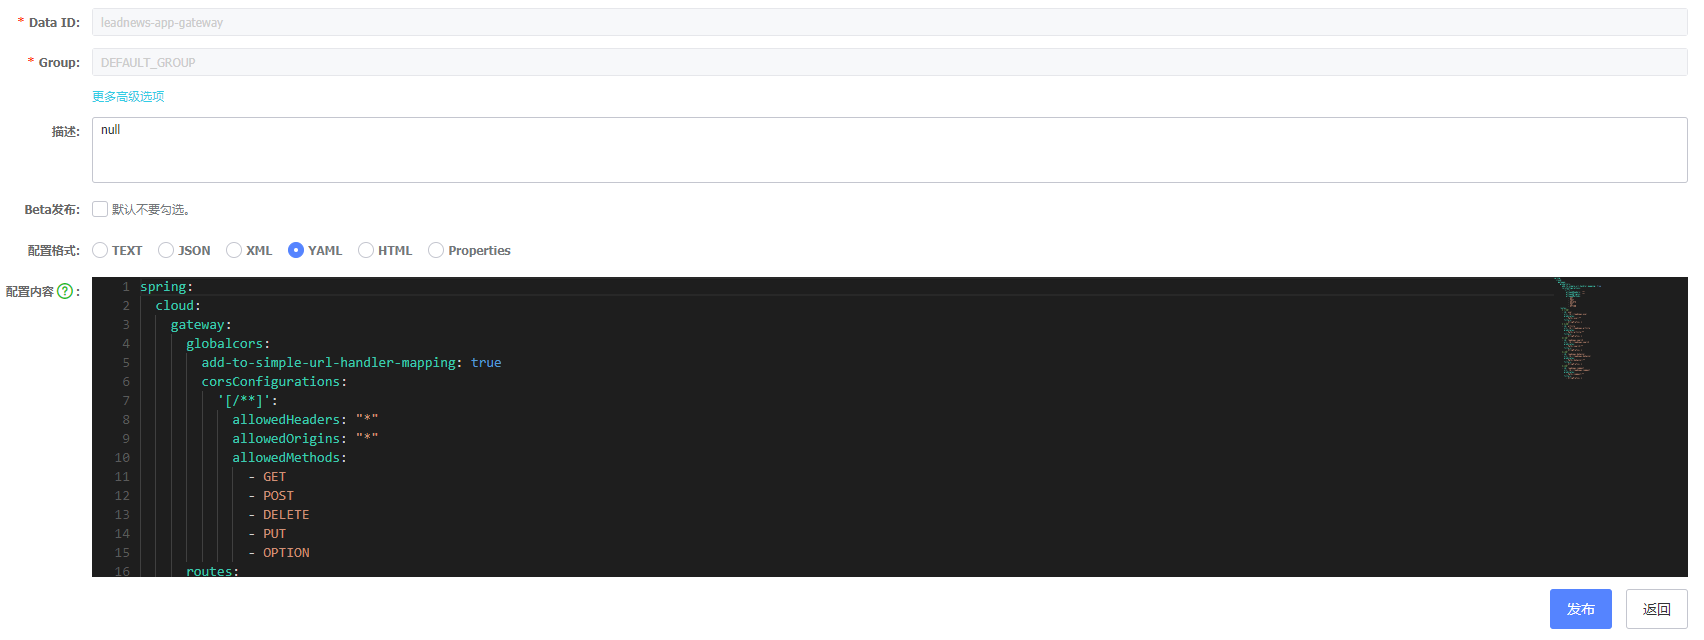

```yaml
spring:
  cloud:
    gateway:
      globalcors:
        add-to-simple-url-handler-mapping: true
        corsConfigurations:
          '[/**]':
            allowedHeaders: "*"
            allowedOrigins: "*"
            allowedMethods:
              - GET
              - POST
              - DELETE
              - PUT
              - OPTION
      routes:
        # 平台管理
        - id: user
          uri: lb://leadnews-user
          predicates:
            - Path=/user/**
          filters:
            - StripPrefix= 1
```



环境搭建完成以后，启动项目网关和用户两个服务，使用postman进行测试

请求地址：http://<gateway-host>:51601/user/api/v1/login/login_auth   

### 1.3 全局过滤器实现jwt校验

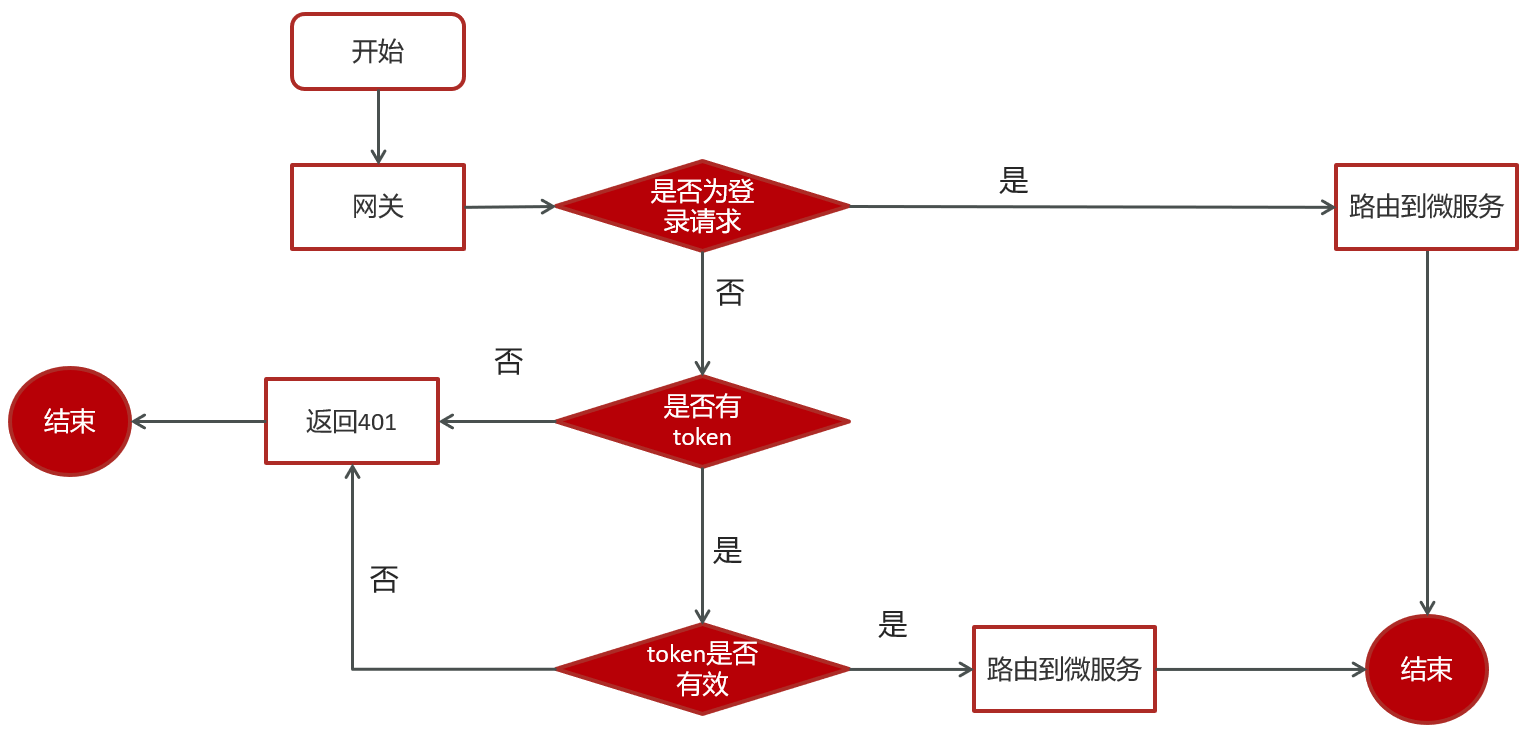

思路分析：

1. 用户进入网关开始登陆，网关过滤器进行判断，如果是登录，则路由到后台管理微服务进行登录
2. 用户登录成功，后台管理微服务签发JWT TOKEN信息返回给用户
3. 用户再次进入网关开始访问，网关过滤器接收用户携带的TOKEN 
4. 网关过滤器解析TOKEN ，判断是否有权限，如果有，则放行，如果没有则返回未认证错误



具体实现：

第一：

​	在认证过滤器中需要用到jwt的解析，所以需要把工具类拷贝一份到网关微服务

第二：

在网关微服务中新建全局过滤器：

```java
package com.heima.app.gateway.filter;


import com.heima.app.gateway.util.AppJwtUtil;
import io.jsonwebtoken.Claims;
import lombok.extern.slf4j.Slf4j;
import org.apache.commons.lang.StringUtils;
import org.springframework.cloud.gateway.filter.GatewayFilterChain;
import org.springframework.cloud.gateway.filter.GlobalFilter;
import org.springframework.core.Ordered;
import org.springframework.http.HttpStatus;
import org.springframework.http.server.reactive.ServerHttpRequest;
import org.springframework.http.server.reactive.ServerHttpResponse;
import org.springframework.stereotype.Component;
import org.springframework.web.server.ServerWebExchange;
import reactor.core.publisher.Mono;

@Component
@Slf4j
public class AuthorizeFilter implements Ordered, GlobalFilter {
    @Override
    public Mono<Void> filter(ServerWebExchange exchange, GatewayFilterChain chain) {
        //1.获取request和response对象
        ServerHttpRequest request = exchange.getRequest();
        ServerHttpResponse response = exchange.getResponse();

        //2.判断是否是登录
        if(request.getURI().getPath().contains("/login")){
            //放行
            return chain.filter(exchange);
        }


        //3.获取token
        String token = request.getHeaders().getFirst("token");

        //4.判断token是否存在
        if(StringUtils.isBlank(token)){
            response.setStatusCode(HttpStatus.UNAUTHORIZED);
            return response.setComplete();
        }

        //5.判断token是否有效
        try {
            Claims claimsBody = AppJwtUtil.getClaimsBody(token);
            //是否是过期
            int result = AppJwtUtil.verifyToken(claimsBody);
            if(result == 1 || result  == 2){
                response.setStatusCode(HttpStatus.UNAUTHORIZED);
                return response.setComplete();
            }
        }catch (Exception e){
            e.printStackTrace();
            response.setStatusCode(HttpStatus.UNAUTHORIZED);
            return response.setComplete();
        }

        //6.放行
        return chain.filter(exchange);
    }

    /**
     * 优先级设置  值越小  优先级越高
     * @return
     */
    @Override
    public int getOrder() {
        return 0;
    }
}
```

测试：

启动user服务，继续访问其他微服务，会提示需要认证才能访问，这个时候需要在heads中设置设置token才能正常访问。


## 9.前端集成

### 9.1)前端项目部署思路

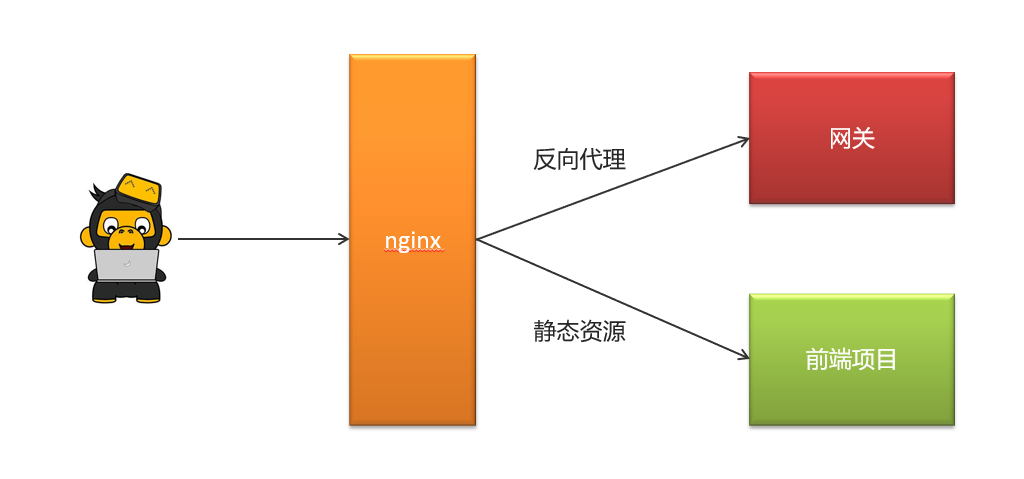

通过nginx来进行配置，功能如下

- 通过nginx的反向代理功能访问后台的网关资源
- 通过nginx的静态服务器功能访问前端静态页面

### 9.2)配置nginx

①：解压资料文件夹中的压缩包nginx-1.18.0.zip

②：解压资料文件夹中的前端项目app-web.zip

③：配置nginx.conf文件

在nginx安装的conf目录下新建一个文件夹`leadnews.conf`,在当前文件夹中新建`heima-leadnews-app.conf`文件

heima-leadnews-app.conf配置如下：

```javascript
upstream  heima-app-gateway{
    server <gateway-host>:51601;
}

server {
	listen 8801;
	location / {
		root <app-web-directory>/;
		index index.html;
	}
	
	location ~/app/(.*) {
		proxy_pass http://heima-app-gateway/$1;
		proxy_set_header HOST $host;  # 不改变源请求头的值
		proxy_pass_request_body on;  #开启获取请求体
		proxy_pass_request_headers on;  #开启获取请求头
		proxy_set_header X-Real-IP $remote_addr;   # 记录真实发出请求的客户端IP
		proxy_set_header X-Forwarded-For $proxy_add_x_forwarded_for;  #记录代理信息
	}
}
```

nginx.conf   把里面注释的内容和静态资源配置相关删除，引入heima-leadnews-app.conf文件加载

```javascript

#user  nobody;
worker_processes  1;

events {
    worker_connections  1024;
}
http {
    include       mime.types;
    default_type  application/octet-stream;
    sendfile        on;
    keepalive_timeout  65;
	# 引入自定义配置文件
	include leadnews.conf/*.conf;
}
```

④ ：启动nginx

​    在nginx安装包中使用命令提示符打开，输入命令nginx启动项目

​    可查看进程，检查nginx是否启动

​	重新加载配置文件：`nginx -s reload`

⑤：打开前端项目进行测试  -- >  http://localhost:8801

​     用谷歌浏览器打开，调试移动端模式进行访问
